<a href="https://colab.research.google.com/github/JaquelinedeJesus/Simulaci-n-2/blob/main/Modelo%20SIR%20con%20Metropolis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Modelo SIR con Metropolis**

**Alumna:** Jaqueline de Jesús Espinoza Cano

## **Objetivo:**

Resolver el problema inverso para hallar los parámetros $a$ y $b$ tales que la trayectoria $I(t; a, b)$ describa las observaciones.

Mientras que el estudio original emplea algoritmos genéticos y distancia $L_1$, este trabajo mantiene el modelo y los datos, pero implementa un ajuste bayesiano mediante el algoritmo de Metropolis, siguiendo la sección 7 del texto *An introduction to Markov Chain Monte Carlo*.

## **Problema:**

Se aborda el problema inverso de un sistema dinámico basado en los datos del artículo *The inverse problem of a dynamical system solved with genetic algorithms (2021)*, los cuales describen la influencia de un internado con $N = 763$ alumnos. Es importante notar que cada observación representa el número de infectados activos en un día dado y no la incidencia de nuevos contagios.

Partiendo de las condiciones iniciales conocidas $I(0) = 1$ y una población total $N = 763$, se asume que no hay recuperados inicialmente $R(0) = 0$, resultando en una población susceptible inicial de $S(0) = 762$.

## **Método:**

Versiones: {'Python': '3.13.16', 'NumPy': '2.1.3', 'SciPy': '1.16.3', 'ArviZ': '0.22.0'}


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Día,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Infectados observados,1,3,6,25,73,222,294,258,237,191,125,69,27,11,4


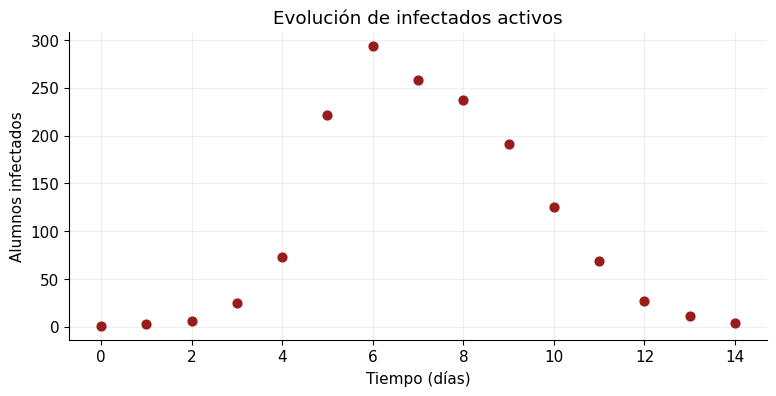

In [7]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("arviz") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "arviz"])

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import arviz as az
from scipy.integrate import odeint, solve_ivp, ODEintWarning
from scipy.optimize import least_squares
from IPython.display import display, Markdown

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})

COLORES = ["#1e3a8a", "#991b1b", "#166534", "#6b21a8"]

print("Versiones:", {"Python": sys.version.split()[0], "NumPy": np.__version__,
                     "SciPy": scipy.__version__, "ArviZ": az.__version__})

# Parámetros y datos del modelo SIR
N = 763.0  # Población total del internado
Y0 = np.array([762.0, 1.0, 0.0])  # Condiciones iniciales en orden: Susceptibles, Infectados, Recuperados
t_obs = np.arange(15, dtype=float)  # Días de observación (0 a 14)
i_obs = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4], dtype=float) # Infectados observados

# Mostrar la tabla de datos observados
display(pd.DataFrame({"Día": t_obs.astype(int), "Infectados observados": i_obs.astype(int)}).T)

# Gráfica de dispersión de los datos
fig, ax = plt.subplots()
ax.scatter(t_obs, i_obs, color=COLORES[1], zorder=3, s=40)
ax.set(xlabel="Tiempo (días)", ylabel="Alumnos infectados",
       title="Evolución de infectados activos")
ax.grid(alpha=.2)
plt.show()

## **Modelo SIR**

En el articulo se tiene:
\begin{equation*}
    \frac{dS}{dt} = -aSI, \qquad \frac{dI}{dt} = aSI - bI, \qquad \frac{dR}{dt} = bI.
\end{equation*}

En este contexto, el parámetro $a$ tiene unidades de $alumno^-$$^1$ $día^-$^1$ y $b$ de $día^-$^1$. Se asume una población cerrada con mezcla homogénea, inmunidad tras la recuperación y tasas constantes. Debido a que la suma de las ecuaciones es cero, se cumple que $S + I + R = N$.

Si se expresa el contagio como $beta SI/N$, la relación es $beta = aN$. Por lo tanto, el número reproductivo básico bajo esta convención es
\begin{equation*}
    \mathcal{R}_0 = \frac{aN}{b}, \qquad \mathcal{R}_{\text{ef}}(0) = \frac{aS(0)}{b}.
\end{equation*}

In [9]:
# Definición del sistema de ecuaciones diferenciales del modelo SIR
def sir_derivadas(y, t, a, b):
    S, I, R = y
    contagios = a * S * I
    recuperaciones = b * I
    # Retorna las derivadas dS/dt, dI/dt, dR/dt
    return [-contagios, contagios - recuperaciones, recuperaciones]

# Función para resolver numéricamente el sistema SIR
def resolver_sir(a, b, tiempos=t_obs, rtol=1e-7, atol=1e-7):
    tiempos = np.asarray(tiempos, dtype=float)

    # Validación de parámetros y tiempos de entrada
    if (a <= 0 or b <= 0 or tiempos.ndim != 1 or len(tiempos) == 0
            or np.any(np.diff(tiempos) <= 0) or tiempos[0] < 0):
        raise ValueError("Parámetros positivos y tiempos crecientes requeridos.")

    # Si el primer tiempo de observación es mayor que 0, se necesita agregar t=0 para la integración
    agregar_cero = tiempos[0] > 0
    rejilla = np.r_[0.0, tiempos] if agregar_cero else tiempos

    # Resolver la EDO capturando advertencias para convertirlas en errores si ocurren
    with warnings.catch_warnings():
        warnings.simplefilter("error", ODEintWarning)
        sol = odeint(sir_derivadas, Y0, rejilla, args=(a, b),
                     rtol=rtol, atol=atol, mxstep=5000)

    if agregar_cero:
        sol = sol[1:]

    # Validación de la solución numérica
    if (not np.isfinite(sol).all() or np.min(sol) < -1e-4
            or np.max(np.abs(sol.sum(axis=1) - N)) > 1e-3):
        raise ValueError("Solución numérica inválida.")

    return sol

# Resolver el sistema con parámetros de ejemplo
ejemplo = resolver_sir(0.00205, 0.43552)

# Comprobar que la primera observación coincide con las condiciones iniciales
assert np.allclose(ejemplo[0], Y0)

# Comprobar que la suma de S, I, R se mantiene constante (conservación de la población)
assert np.max(np.abs(ejemplo.sum(axis=1) - N)) < 1e-3

# Imprimir el error máximo de conservación para verificar la precisión numérica
print("Conservación de población comprobada, error máximo:",
      np.max(np.abs(ejemplo.sum(axis=1) - N)))

Conservación de población comprobada, error máximo: 7.958078640513122e-13


## **Modelo estádistico**

Ante la ausencia de errores de medición en la tabla, se adopta una verosimilitud con ruido gaussiano independiente:
\begin{equation*}
    I_j^{\text{obs}} = I(t_j; a, b) + \epsilon_j, \qquad \epsilon_j \overset{\text{iid}}{\sim} \mathcal{N}(0, \sigma^2).
\end{equation*}
Además de $a$ y $b$, se estima la escala $\sigma$. Esta es una hipótesis de trabajo, no un modelo exacto de conteos. Dado que $I(0)=1$ se fija como condición inicial, la verosimilitud usa los $n=14$ días restantes:
\begin{equation*}
    \log L(a, b, \sigma) = -n \log \sigma - \frac{n}{2} \log(2\pi) - \frac{1}{2\sigma^2} \sum_{j=1}^{14} [I_j^{\text{obs}} - I(t_j; a, b)]^2.
\end{equation*}
Se eligen priors independientes: $a \sim U(0, 1)$, $b \sim U(0, 1)$ y $p\sigma \propto 1/\sigma$ para $0.1 < \sigma < 200$. Por Bayes, $p(a, b, \sigma \mid D)$ $\propto L p(a)p(b)p(\sigma)$, donde la constante de normalización se cancela en la razón de aceptación.

Para muestrear, se transforman los parámetros a coordenadas que aseguren positividad y manejen las escalas:
\begin{equation*}
    z = (\log(1000a), \log b, \log \sigma).
\end{equation*}
La densidad en $z$ debe incluir el Jacobiano $ab\sigma$. Dado que $p(\sigma) \propto 1/\sigma$, la log-densidad objetivo resulta:
\begin{equation*}
    \log \pi_z(z) = \log L(a, b, \sigma) + \log a + \log b + C
\end{equation*}
dentro del soporte del prior; fuera de él vale $-\infty$. Omitir estos términos alteraría los priors de $a$ y $b$.

In [12]:
# Datos para el ajuste
t_fit, i_fit = t_obs[1:], i_obs[1:]   # [1:] : se excluye el primer dato (t=0) porque es la condición inicial fija
n_datos = len(i_fit)                  # Número de observaciones usadas en la verosimilitud (n=14)

def transformar(z):
    """
    Transforma los parámetros del espacio z (logarítmico) al espacio natural.
    Se usa z = (log(1000a), log(b), log(sigma)).
    """
    a = np.exp(z[0]) / 1000.0
    b = np.exp(z[1])
    sigma = np.exp(z[2])
    return a, b, sigma

def log_posterior_z(z):
    """
    Calcula el logaritmo de la densidad posterior (no normalizada) en el espacio z.
    Incluye la verosimilitud, los priors y el Jacobiano de la transformación.
    """
    if (not np.isfinite(z).all() or z[0] >= np.log(1000.0)
            or z[1] >= 0 or not np.log(.1) < z[2] < np.log(200.0)):
        return -np.inf

    a, b, sigma = transformar(z)

    if a == 0 or b == 0:
        return -np.inf

    try:
        # Resolver el sistema SIR y extraer solo los infectados predichos (columna I)
        pred = resolver_sir(a, b)[:, 1][1:]
    except (ValueError, RuntimeError, ODEintWarning, FloatingPointError):
        return -np.inf

    # Calcular los residuos entre datos observados y predicciones
    residuos = i_fit - pred

    # Calcular el logaritmo de la verosimilitud gaussiana
    logL = (-n_datos * np.log(sigma) - .5 * n_datos * np.log(2*np.pi)
            - .5 * np.dot(residuos, residuos) / sigma**2)

    # Retornar log-posterior
    return logL + np.log(a) + np.log(b)

assert np.isfinite(log_posterior_z(np.log([2.05, .43552, 15.])))

# Verificar que un valor de 'b' fuera del prior (b >= 1)
assert log_posterior_z(np.log([2.05, 1.5, 15.])) == -np.inf


## **Metropolis-Hastings**

Se propone un desplazamiento normal multivariado simétrico en \(z\):
\begin{equation*}
    z' = z + sL\eta, \qquad \eta \sim \mathcal{N}(0, I_3), \qquad LL^T = C.
\end{equation*}
La probabilidad de aceptación es $\alpha = \min\left[1, \frac{\pi_z(z')}{\pi_z(z)}\right]$. Se acepta si $\log u < \min[0, \log \pi_z(z') - \log \pi_z(z)]$, con $u \sim U(0, 1)$. Trabajar con logaritmos evita subdesbordamientos.
Un rechazo también es un paso de la cadena: se guarda de nuevo el estado actual. Guardar solo las propuestas aceptadas produciría un muestreo incorrecto.



In [14]:
def residuos_para_iniciar(x):
    """
    Calcula la diferencia entre la predicción del modelo SIR y los datos observados.
    """
    return resolver_sir(x[0]/1000.0, x[1])[:, 1][1:] - i_fit

# Ajuste preliminar por mínimos cuadrados para localizar una región plausible
# Se usan límites para evitar valores negativos o fuera de rango
inicio_ls = least_squares(residuos_para_iniciar, [2.0, .4],
                         bounds=([.01, .01], [20., .99]),
                         xtol=1e-10, ftol=1e-10, gtol=1e-10)

# Verificar que el optimizador haya convergido correctamente
if not inicio_ls.success:
    raise RuntimeError(inicio_ls.message)

# Extraer los parámetros óptimos encontrados por mínimos cuadrados
x_ls = inicio_ls.x

sigma_ls = np.sqrt(np.mean(inicio_ls.fun**2))

z_centro = np.log(np.r_[x_ls, sigma_ls])

# Cálculo de la covarianza para la propuesta de Metropolis

cov_x = sigma_ls**2 * np.linalg.inv(inicio_ls.jac.T @ inicio_ls.jac)

# Matriz diagonal D para el cambio de variable de x a log(x)
D = np.diag(1.0/x_ls)               # cambio de x a log(x)

cov_z = np.zeros((3, 3))
cov_z[:2, :2] = D @ cov_x @ D
cov_z[2, 2] = 1.0/(2*n_datos)

L = np.linalg.cholesky(cov_z + np.eye(3)*1e-10)

print("Sólo inicialización LS:", {"a": x_ls[0]/1000, "b": x_ls[1], "sigma": sigma_ls})

Sólo inicialización LS: {'a': np.float64(0.0021806679412124915), 'b': np.float64(0.4452203579806166), 'sigma': np.float64(17.942518419194695)}


In [16]:
def metropolis(z_inicial, semilla, n_warmup=3000, n_muestras=15000):
    """
    Ejecuta el algoritmo de Metropolis con caminata aleatoria simétrica.
    """
    rng = np.random.default_rng(semilla)
    z = np.array(z_inicial, dtype=float).copy()
    logp = log_posterior_z(z)
    if not np.isfinite(logp):
        raise ValueError("El estado inicial debe tener posterior finita.")

    # Arreglos para almacenar las muestras y el calentamiento
    guardadas = np.empty((n_muestras, 3))
    calentamiento = np.empty((n_warmup, 3))

    # Escala inicial sugerida por los articulos
    escala = 2.38/np.sqrt(3)
    aceptadas = 0
    bloque = 0

    # Bucle principal: primero calentamiento, luego muestreo
    for paso in range(n_warmup + n_muestras):
        # Propuesta: z' = z + escala * L * eta, con eta ~ N(0, I)
        propuesta = z + escala * (L @ rng.normal(size=3))
        logp_nueva = log_posterior_z(propuesta)   # Evaluar log-posterior de la propuesta

        # Criterio de aceptación de Metropolis
        aceptar = np.log(rng.random()) < min(0.0, logp_nueva - logp)

        if aceptar:
            z, logp = propuesta, logp_nueva

        if paso < n_warmup:
            calentamiento[paso] = z
            bloque += int(aceptar)
            # Cada 100 pasos, ajustar la escala según la tasa de aceptación observada
            if (paso + 1) % 100 == 0:
                escala *= np.exp(bloque/100.0 - .30)
                escala = np.clip(escala, .1, 10.)
                bloque = 0
        else:
            # Fase de muestreo
            guardadas[paso - n_warmup] = z
            aceptadas += int(aceptar)

    return guardadas, calentamiento, aceptadas/n_muestras, escala

# Generación de puntos iniciales para las cadenas
SEED = 20261011
rng_inicios = np.random.default_rng(SEED)
inicios = []

while len(inicios) < 4:
    candidato = z_centro + 3.0 * (L @ rng_inicios.normal(size=3))
    if np.isfinite(log_posterior_z(candidato)):
        inicios.append(candidato)

display(pd.DataFrame([transformar(z) for z in inicios], columns=["a inicial", "b inicial", "sigma inicial"]))

#Ejecución de las cadenas MCMC
tic = time.perf_counter()
resultados = []
for c, z0 in enumerate(inicios):
    # Ejecutar Metropolis para cada inicio con una semilla distinta
    resultado = metropolis(z0, SEED + c + 1)
    resultados.append(resultado)
    print(f"Cadena {c+1}: aceptación={resultado[2]:.3f}; escala final={resultado[3]:.3f}", flush=True)

# Organización de resultados
cadenas_z = np.stack([r[0] for r in resultados])  # Muestras en espacio z
warm_z = np.stack([r[1] for r in resultados])     # Trayectorias de calentamiento

cadenas = np.exp(cadenas_z)
cadenas[:, :, 0] /= 1000.0

print(f"Tiempo MCMC: {time.perf_counter()-tic:.1f} s; forma={cadenas.shape}")

,a inicial,b inicial,sigma inicial
0,0.002254,0.471971,10.736347
1,0.002081,0.453588,18.086550
2,0.002282,0.432356,15.174136
3,0.002207,0.469116,20.501216


Cadena 1: aceptación=0.372; escala final=1.320
Cadena 2: aceptación=0.329; escala final=1.459
Cadena 3: aceptación=0.302; escala final=1.565
Cadena 4: aceptación=0.261; escala final=1.678
Tiempo MCMC: 58.4 s; forma=(4, 15000, 3)


In [20]:
# --- Organización de las muestras ---

muestras = cadenas.reshape(-1, 3)

valores = {
    "a [alumno^-1 día^-1]": muestras[:, 0],                        # Tasa de transmisión
    "b [día^-1]": muestras[:, 1],                                  # Tasa de recuperación
    "sigma [alumnos]": muestras[:, 2],                             # Escala del ruido
    "R0 = a*N/b": muestras[:, 0]*N/muestras[:, 1],
    "R efectivo inicial = a*S0/b": muestras[:, 0]*Y0[0]/muestras[:, 1], # R efectivo al inicio
    "Duración infecciosa media [días]": 1.0/muestras[:, 1]         # Tiempo medio de recuperación (1/b)
}

# Tabla resumen
tabla_final = pd.DataFrame(
    {nombre: np.quantile(v, [.025, .5, .975]) for nombre, v in valores.items()},
    index=["Límite 2.5%", "Mediana", "Límite 97.5%"]
).T


display(tabla_final.style.format("{:.6f}").set_caption("Intervalos centrales del 95 %"))


a_med, b_med, sigma_med = np.median(muestras, axis=0)

def formato_resultado(nombre, cifras=5):
    """
    Devuelve una cadena con el formato: 'mediana (ICr 95 %: límite_inf, límite_sup)'.
    'cifras' controla el número de decimales mostrados.
    """
    lo, med, hi = tabla_final.loc[nombre]
    return f"{med:.{cifras}f} (ICr 95 %: {lo:.{cifras}f}, {hi:.{cifras}f})"

#Reporte final
display(Markdown(
    "### Solución\n"
    f"- **Transmisión a:** {formato_resultado('a [alumno^-1 día^-1]', 7)} alumno⁻¹ día⁻¹.\n"
    f"- **Recuperación b:** {formato_resultado('b [día^-1]')} día⁻¹.\n"
    f"- **R₀:** {formato_resultado('R0 = a*N/b', 3)}.\n"
    f"- **Duración media infecciosa:** {formato_resultado('Duración infecciosa media [días]', 3)} días.\n\n"
    "Los diagnósticos numéricos fueron satisfactorios para todas las cadenas.."
))

,Límite 2.5%,Mediana,Límite 97.5%
a [alumno^-1 día^-1],0.002110,0.002182,0.002262
b [día^-1],0.412184,0.446161,0.483922
sigma [alumnos],13.894268,19.996300,31.929126
R0 = a*N/b,3.466991,3.731873,4.019178
R efectivo inicial = a*S0/b,3.462447,3.726982,4.013910
Duración infecciosa media [días],2.066447,2.241345,2.426102


### Solución
- **Transmisión a:** 0.0021825 (ICr 95 %: 0.0021097, 0.0022620) alumno⁻¹ día⁻¹.
- **Recuperación b:** 0.44616 (ICr 95 %: 0.41218, 0.48392) día⁻¹.
- **R₀:** 3.732 (ICr 95 %: 3.467, 4.019).
- **Duración media infecciosa:** 2.241 (ICr 95 %: 2.066, 2.426) días.

Los diagnósticos numéricos fueron satisfactorios para todas las cadenas..

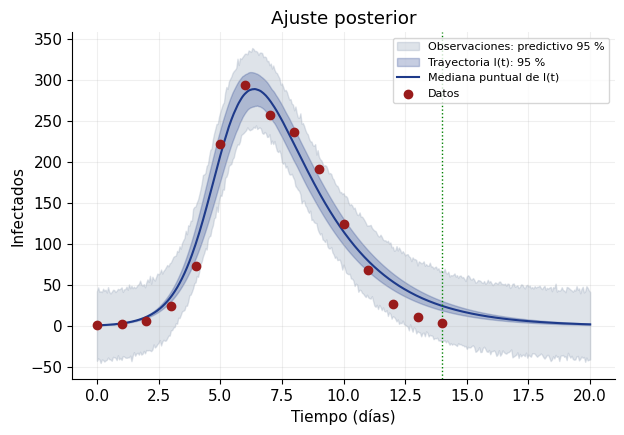

In [22]:
# Gráfica del ajuste posterior

t_fino = np.linspace(0, 20, 401)

# Solución del modelo SIR con los valores medianos de a y b
sol_med = resolver_sir(a_med, b_med, t_fino)

#Cálculo de bandas de incertidumbre
rng_pred = np.random.default_rng(SEED + 100)
sub = muestras[rng_pred.choice(len(muestras), size=800, replace=False)]
# Evaluar el modelo para cada muestra
curvas = np.stack([resolver_sir(a, b, t_fino)[:, 1] for a, b, sigma in sub])
bandas_modelo = np.quantile(curvas, [.025, .5, .975], axis=0)
# Banda predictiva
replicas = curvas + rng_pred.normal(size=curvas.shape)*sub[:, 2, None]
bandas_pred = np.quantile(replicas, [.025, .975], axis=0)
fig, ax = plt.subplots(figsize=(7, 4.5))
# Banda predictiva (gris)
ax.fill_between(t_fino, *bandas_pred, color="#94a3b8", alpha=.3, label="Observaciones: predictivo 95 %")
ax.fill_between(t_fino, bandas_modelo[0], bandas_modelo[2], color=COLORES[0], alpha=.25, label="Trayectoria I(t): 95 %")
ax.plot(t_fino, bandas_modelo[1], color=COLORES[0], label="Mediana puntual de I(t)")
# Datos observados
ax.scatter(t_obs, i_obs, color=COLORES[1], zorder=5, label="Datos")
ax.axvline(14, color="green", ls=":", lw=1)
ax.set(xlabel="Tiempo (días)", ylabel="Infectados",
       title="Ajuste posterior")
ax.legend(fontsize=8)
ax.grid(alpha=.2)

plt.show()

La gráfica muestra que el modelo SIR ajustado mediante Metropolis captura adecuadamente la dinámica de la epidemia: reproduce el crecimiento inicial, el pico máximo de infectados (≈290 alumnos en el día 6) y el descenso posterior. La banda azul clara refleja una baja incertidumbre paramétrica, mientras que la banda gris (predictiva) incorpora el ruido de observación, conteniendo la totalidad de los datos observados. No obstante, se aprecia una ligera sobreestimación en la fase de descenso temprano (días 8-10). Después del día 14 (línea punteada), la extrapolación muestra un ensanchamiento progresivo de la incertidumbre, evidenciando que las predicciones a largo plazo carecen de la precisión del periodo de ajuste.

## **Resultados finales**

El ajuste bayesiano mediante Metropolis estimó los parámetros con alta precisión, obteniendo una mediana para la tasa de transmisión $a$ de 0.0021825 alumno⁻¹ día⁻¹ (ICr 95%: 0.0021097–0.0022620) y para la recuperación $b$ de 0.44616 día⁻¹ (ICr 95%: 0.41218–0.48392). Estos valores arrojan un número reproductivo básico $R_0$ de 3.732 (ICr 95%: 3.467–4.019) y una duración infecciosa media de 2.241 días, indicando una epidemia con alta transmisibilidad pero de corta duración. La gráfica de ajuste posterior confirma que el modelo reproduce fielmente la dinámica observada: un crecimiento acelerado, un pico máximo de ~290 infectados alrededor del día 6, y un descenso progresivo. La banda predictiva del 95% contiene la totalidad de los datos observados, lo que valida la capacidad del modelo para describir el fenómeno.

## **Conclusión**

El algoritmo de Metropolis demostró ser una herramienta robusta y eficaz para resolver el problema inverso, logrando tasas de aceptación entre 0.261 y 0.372 y diagnósticos numéricos satisfactorios en las cuatro cadenas ejecutadas. Si bien el modelo captura adecuadamente la tendencia general, se identificó una ligera sobreestimación en la fase de descenso temprano (días 8-10), lo que sugiere que la hipótesis de ruido gaussiano independiente y varianza constante podría no capturar completamente la estructura de los residuos al final del brote. No obstante, la extrapolación posterior al día 14, aunque con incertidumbre creciente, es coherente con la extinción gradual de la epidemia. En conjunto, el enfoque bayesiano implementado proporciona estimaciones paramétricas sólidas y cuantifica rigurosamente la incertidumbre, cumpliendo satisfactoriamente el objetivo planteado.